# 5.3 Análisis cualitativo, robustez y discusión

En esta sección analizamos en qué regiones de la imagen se apoyan los modelos (Grad-CAM), identificamos los casos difíciles, medimos la caída de desempeño ante perturbaciones controladas, incluida la sustitución del fondo, y discutimos los resultados del capítulo.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


In [2]:
import torch
from src.analysis import PERTURBATIONS, perturbed_test_set, robustness_run
from src.data import load_cache, prepare_common

COMPUTE = True        # calcula solo lo que falte; si todo existe, no recalcula nada
common = prepare_common()
cache = load_cache()
sp = common["splits"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
df = load_pickle(C.SUMMARY / "metricas_por_corrida.pkl")
seeds = sorted(df["seed"].unique())
med = load_pickle(C.SUMMARY / "semilla_mediana.pkl")
# imágenes de prueba en el orden de las predicciones guardadas
p0 = load_pickle(C.run_dir(C.MODELS[0], seeds[0]) / "test_predictions.pkl")
pos = {r: i for i, r in enumerate(sp["test"]["relpath"])}
pos_test = np.array([pos[f] for f in p0["filepaths"]])
rows_test, y = sp["test"]["rows"][pos_test], p0["y_true"]
relp = [sp["test"]["relpath"][i] for i in pos_test]
print("Dispositivo:", device, "| semillas:", seeds, "| imágenes de prueba:", len(y))

Dispositivo: cuda | semillas: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)] | imágenes de prueba: 361


## Robustez ante perturbaciones

Evaluamos el mejor modelo de cada semilla en el conjunto de prueba perturbado. Las perturbaciones se aplican en $[0, 1]$, antes de normalizar, con una semilla fija, de modo que todos los modelos y semillas se evalúan sobre las mismas imágenes.

| Perturbación | Definición |
|---|---|
| ruido 0.05 / 0.10 | ruido gaussiano con $\sigma$ = 0.05 o 0.10 |
| desenfoque | filtro gaussiano 9×9, $\sigma$ = 2 |
| brillo −30 / +30 | intensidad × 0.7 o × 1.3 |
| oclusión | cuadro gris de 56×56 en posición aleatoria |
| fondo sustituido | píxeles de fondo claro (mínimo RGB ≥ 200) reemplazados por un color aleatorio por imagen |

La sustitución del fondo evalúa el atajo identificado en la sección 2.7: si un modelo depende del fondo blanco, su desempeño cae aunque el objeto permanezca intacto.

In [3]:
if COMPUTE:
    faltan = [(m, s) for m in C.MODELS for s in seeds if not (C.run_dir(m, s) / "robustness.pkl").exists()]
    if faltan:
        sets = {k: perturbed_test_set(cache, sp["test"]["rows"], k) for k in PERTURBATIONS}
        for m, s in faltan:
            robustness_run(m, C.run_dir(m, s), common, cache, device, sets)
        print(f"Calculadas {len(faltan)} evaluaciones de robustez")

rob = []
for m in C.MODELS:
    for s in seeds:
        r = load_pickle(C.run_dir(m, s) / "robustness.pkl")["results"]
        for k in PERTURBATIONS:
            rob.append({"modelo": m, "semilla": s, "perturbación": k, "F1": r[k]["f1_macro"],
                        "caída": r["limpio"]["f1_macro"] - r[k]["f1_macro"]})
rob = pd.DataFrame(rob)
res_rob = rob.groupby(["perturbación", "modelo"])["F1"].agg(["mean", "std"]).unstack("modelo")
caida = rob.groupby(["perturbación", "modelo"])["caída"].agg(["mean", "std"]).unstack("modelo")
tab = pd.DataFrame({m: [f"{res_rob.loc[k, ('mean', m)]:.3f} ± {res_rob.loc[k, ('std', m)]:.3f}" for k in PERTURBATIONS]
                    for m in C.MODELS}, index=PERTURBATIONS)
display(tab)

,CNN,MobileNetV2,ResNet-18
limpio,0.826 ± 0.022,0.810 ± 0.025,0.863 ± 0.022
ruido_0.05,0.185 ± 0.025,0.276 ± 0.054,0.394 ± 0.048
ruido_0.10,0.132 ± 0.030,0.094 ± 0.026,0.116 ± 0.040
desenfoque,0.360 ± 0.041,0.504 ± 0.050,0.608 ± 0.048
brillo_-30,0.720 ± 0.036,0.710 ± 0.033,0.753 ± 0.015
brillo_+30,0.741 ± 0.031,0.748 ± 0.024,0.810 ± 0.020
oclusion,0.781 ± 0.023,0.764 ± 0.022,0.822 ± 0.013
fondo_sustituido,0.568 ± 0.031,0.602 ± 0.035,0.606 ± 0.028


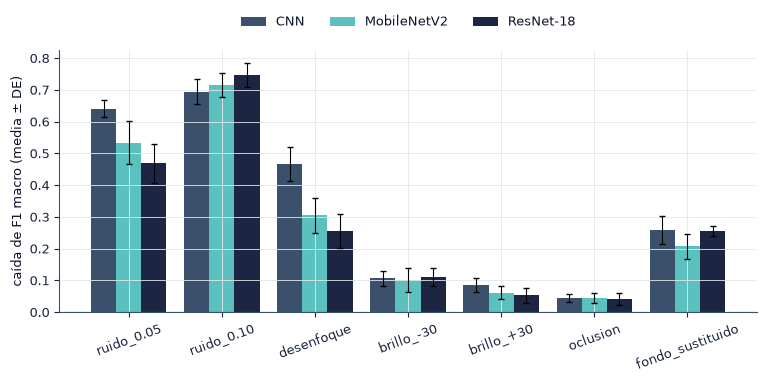

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
pert = [k for k in PERTURBATIONS if k != "limpio"]
x = np.arange(len(pert))
for i, m in enumerate(C.MODELS):
    ax.bar(x + (i - 1) * 0.27, caida.loc[pert, ("mean", m)], 0.27, yerr=caida.loc[pert, ("std", m)],
           color=P.color(m), label=m, capsize=2, error_kw={"lw": 0.8})
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, pert, rotation=20)
ax.set_ylabel("caída de F1 macro (media ± DE)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
P.save(fig, "5_3_robustez", rob)
plt.show()

In [5]:
from src import stats as S

caida_fondo = rob[rob["perturbación"] == "fondo_sustituido"].pivot(index="semilla", columns="modelo", values="caída")[C.MODELS]
pares_fondo = S.pairwise(caida_fondo)
print("Comparación pareada de la caída de F1 con fondo sustituido:")
display(pares_fondo[["A", "B", "dif_media", "ic_t_lo", "ic_t_hi", "p_wilcoxon", "p_wilcoxon_holm"]].round(4))

Comparación pareada de la caída de F1 con fondo sustituido:


,A,B,dif_media,ic_t_lo,ic_t_hi,p_wilcoxon,p_wilcoxon_holm
0,CNN,MobileNetV2,0.0508,-0.0031,0.1047,0.1094,0.2188
1,CNN,ResNet-18,0.0017,-0.0376,0.0411,0.9453,0.9453
2,MobileNetV2,ResNet-18,-0.0490,-0.0878,-0.0103,0.0078,0.0234


Para separar el efecto del fondo de la sensibilidad general a perturbaciones, calculamos en cada corrida el exceso de caída: la caída con fondo sustituido menos la caída media de las perturbaciones genéricas (ruido, desenfoque, brillo y oclusión). Un exceso positivo y significativo (Wilcoxon unilateral sobre las semillas) indica dependencia del fondo.

In [6]:
from scipy.stats import wilcoxon

genericas = [k for k in PERTURBATIONS if k not in ("limpio", "fondo_sustituido")]
gen = rob[rob["perturbación"].isin(genericas)].groupby(["modelo", "semilla"])["caída"].mean()
fon = rob[rob["perturbación"] == "fondo_sustituido"].set_index(["modelo", "semilla"])["caída"]
exceso = (fon - gen).rename("exceso").reset_index()
filas = []
for m in C.MODELS:
    e = exceso.loc[exceso["modelo"] == m, "exceso"].to_numpy()
    ci = S.mean_ci(e)
    p = float(wilcoxon(e, alternative="greater").pvalue) if np.any(e != 0) else 1.0
    filas.append({"modelo": m, "exceso medio": ci["media"], "IC t inf": ci["ic_t"][0], "IC t sup": ci["ic_t"][1],
                  "Wilcoxon p (exceso > 0)": p})
atajo = pd.DataFrame(filas).set_index("modelo")
display(atajo.round(4))
_ = save_pickle({"tabla": rob, "pares_fondo": pares_fondo, "exceso_fondo": exceso, "atajo": atajo},
                C.SUMMARY / "robustez.pkl")

,exceso medio,IC t inf,IC t sup,Wilcoxon p (exceso > 0)
modelo,,,,
CNN,-0.0815,-0.1137,-0.0493,1.0000
MobileNetV2,-0.0864,-0.1200,-0.0527,1.0000
ResNet-18,-0.0225,-0.0470,0.0020,0.9609


## Grad-CAM

Grad-CAM (Selvaraju et al., 2017) pondera cada mapa de activación $A^c$ de la última capa convolucional por el promedio espacial del gradiente de la clase predicha:

$$\alpha_c = \frac{1}{HW}\sum_{i,j}\frac{\partial y^{\text{clase}}}{\partial A^c_{ij}}, \qquad L = \mathrm{ReLU}\Big(\sum_c \alpha_c A^c\Big).$$

El mapa $L$ se interpola a 224×224. Lo calculamos para las 361 imágenes de prueba con la semilla mediana de cada modelo. Para cuantificar la atención al fondo comparamos, en cada imagen, la fracción de la intensidad del mapa ubicada sobre el fondo claro con la fracción del área que ocupa el fondo; un cociente menor que 1 indica que el mapa se concentra en el objeto.

In [7]:
from src.analysis import background_attention, gradcam_run
import torch.nn.functional as F

f_cam = C.SUMMARY / "gradcam.pkl"
if COMPUTE and not f_cam.exists():
    cam = {}
    rows = rows_test
    for m in C.MODELS:
        p = load_pickle(C.run_dir(m, med[m]) / "test_predictions.pkl")
        mapas = gradcam_run(m, C.run_dir(m, med[m]), common, cache, device, rows, p["y_pred"])
        bg = background_attention(mapas, cache, rows)
        chicos = F.interpolate(torch.from_numpy(mapas.astype(np.float32))[:, None], size=(56, 56),
                               mode="bilinear", align_corners=False)[:, 0].numpy().astype(np.float16)
        cam[m] = {"seed": med[m], "maps56": chicos, "y_pred": p["y_pred"], "y_true": p["y_true"], **bg}
    save_pickle(cam, f_cam)
cam = load_pickle(f_cam)

from scipy.stats import wilcoxon
filas = []
for m in C.MODELS:
    e, a = cam[m]["frac_energia_fondo"], cam[m]["frac_area_fondo"]
    ok = a > 0.05                                   # se excluyen imágenes casi sin fondo visible
    filas.append({"modelo": m, "imágenes": int(ok.sum()), "energía en fondo (media)": e[ok].mean(),
                  "área de fondo (media)": a[ok].mean(), "energía / área (mediana)": np.median(e[ok] / a[ok]),
                  "Wilcoxon p (energía > área)": wilcoxon(e[ok], a[ok], alternative="greater").pvalue})
atencion = pd.DataFrame(filas).set_index("modelo")
display(atencion.round(4))

,imágenes,energía en fondo (media),área de fondo (media),energía / área (mediana),Wilcoxon p (energía > área)
modelo,,,,,
CNN,263,0.2075,0.295,0.6678,1.0
MobileNetV2,263,0.2090,0.295,0.6499,1.0
ResNet-18,263,0.2080,0.295,0.6832,1.0


**Grad-CAM: aciertos de los tres modelos (2 por clase)**

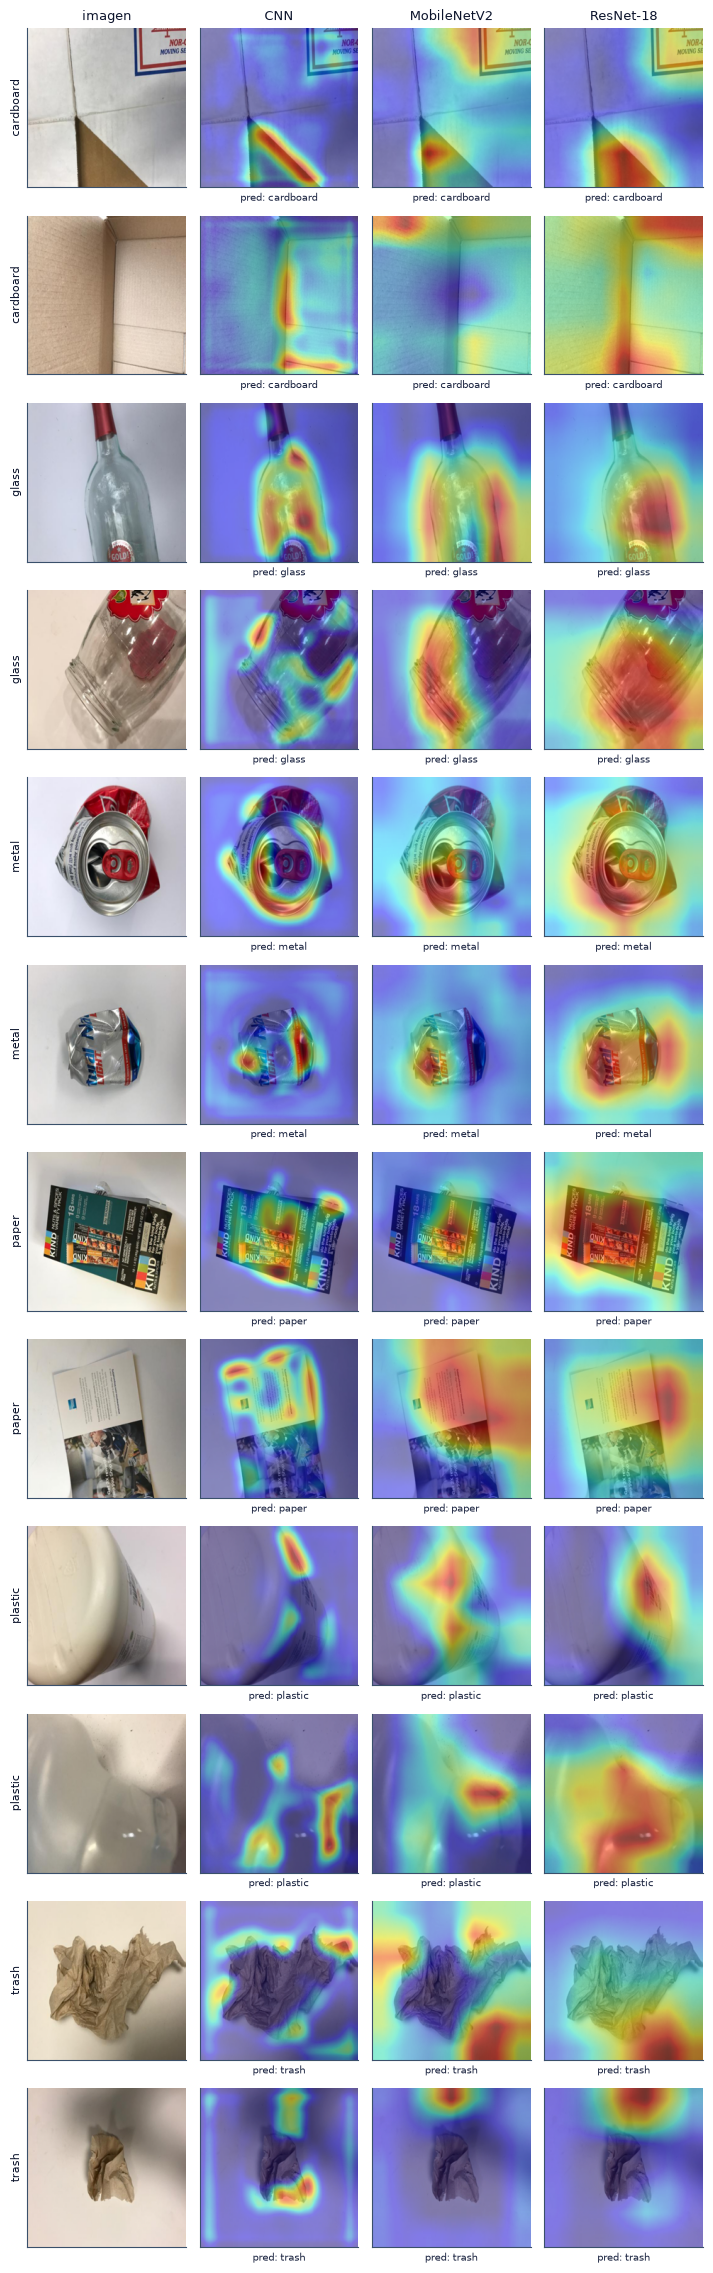

**Grad-CAM: errores (2 por clase; en rojo, predicción incorrecta)**

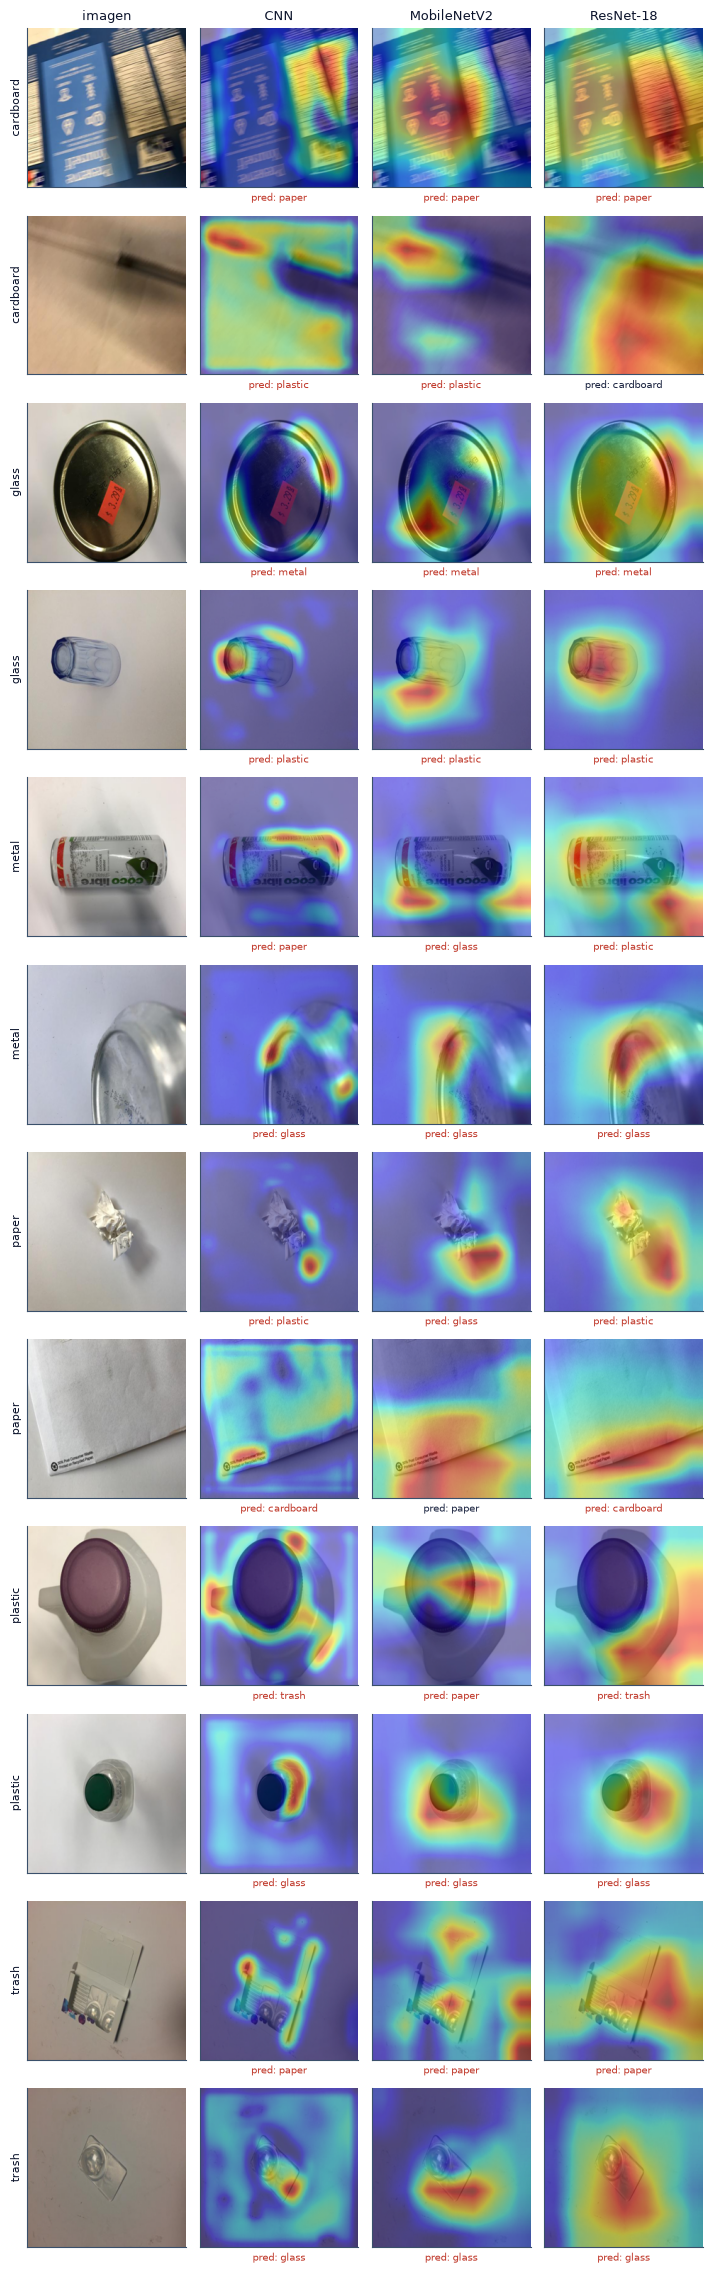

In [8]:
ok_all = np.all([cam[m]["y_pred"] == y for m in C.MODELS], axis=0)
n_err = np.sum([cam[m]["y_pred"] != y for m in C.MODELS], axis=0)
sel = {"aciertos": [], "errores": []}
for k in range(C.NUM_CLASSES):
    idk = np.flatnonzero(y == k)
    sel["aciertos"] += list(idk[ok_all[idk]][:2])
    errs = idk[np.argsort(-n_err[idk], kind="stable")]
    sel["errores"] += list(errs[n_err[errs] > 0][:2])

def figura(indices, titulo, nombre):
    n = len(indices)
    if n == 0:
        print(f"No hay imágenes para «{titulo}».")
        return
    fig, ax = plt.subplots(n, 4, figsize=(7.2, 1.9 * n))
    ax = np.atleast_2d(ax)
    for r, i in enumerate(indices):
        img = cache[rows_test[i]]
        ax[r, 0].imshow(img)
        ax[r, 0].set_ylabel(C.CLASSES[y[i]], fontsize=8)
        for c, m in enumerate(C.MODELS, start=1):
            mp = F.interpolate(torch.from_numpy(cam[m]["maps56"][i].astype(np.float32))[None, None], size=(224, 224),
                               mode="bilinear", align_corners=False)[0, 0].numpy()
            ax[r, c].imshow(img)
            ax[r, c].imshow(mp, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            pred = C.CLASSES[cam[m]["y_pred"][i]]
            ax[r, c].set_xlabel(f"pred: {pred}", fontsize=7, color="#1C2541" if pred == C.CLASSES[y[i]] else "#C0392B")
            if r == 0:
                ax[r, c].set_title(m, fontsize=9)
    ax[0, 0].set_title("imagen", fontsize=9)
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.tight_layout()
    display(Markdown(f"**{titulo}**"))
    P.save(fig, nombre, {"indices_test": list(map(int, indices)), "relpath": [relp[i] for i in indices]})
    plt.show()

figura(sel["aciertos"], "Grad-CAM: aciertos de los tres modelos (2 por clase)", "5_3_gradcam_aciertos")
figura(sel["errores"], "Grad-CAM: errores (2 por clase; en rojo, predicción incorrecta)", "5_3_gradcam_errores")

## Casos difíciles y confusiones frecuentes

19 imágenes de prueba las falla la mayoría de semillas de los tres modelos. Las 12 de mayor pérdida:


,imagen,real,CNN,MobileNetV2,ResNet-18,pérdida media
0,glass/glass278.jpg,glass,paper,paper,paper,8.40
1,plastic/plastic455.jpg,plastic,paper,paper,paper,7.75
2,glass/glass186.jpg,glass,metal,metal,metal,6.98
3,trash/trash53.jpg,trash,cardboard,cardboard,glass,6.13
4,plastic/plastic97.jpg,plastic,paper,paper,paper,5.09
5,trash/trash91.jpg,trash,paper,paper,paper,4.82
6,trash/trash126.jpg,trash,glass,glass,glass,3.49
7,plastic/plastic456.jpg,plastic,metal,metal,metal,3.36
8,plastic/plastic457.jpg,plastic,glass,glass,glass,3.03
9,cardboard/cardboard279.jpg,cardboard,paper,paper,paper,2.89


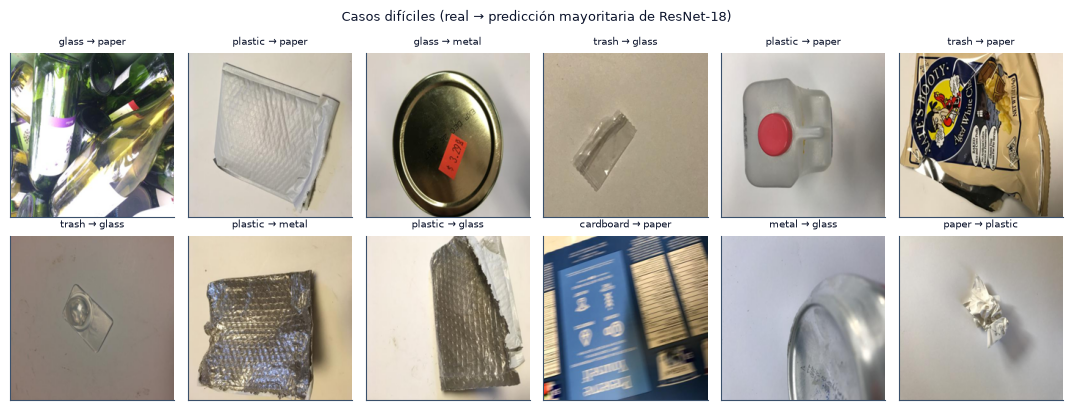

,par,confusiones (ambos sentidos)
7,glass / plastic,259
5,glass / metal,190
12,paper / plastic,180
13,paper / trash,162
2,cardboard / paper,89


In [9]:
perdidas, errados = [], []
for m in C.MODELS:
    for s in seeds:
        p = load_pickle(C.run_dir(m, s) / "test_predictions.pkl")
        perdidas.append(-np.log(np.clip(p["probs"][np.arange(len(y)), y], 1e-12, None)))
        errados.append(p["y_pred"] != y)
perdidas = np.array(perdidas).mean(0)
falla_modelo = np.array(errados).reshape(len(C.MODELS), len(seeds), -1).mean(1) > 0.5   # mayoría de semillas
todos_fallan = falla_modelo.all(0)
dificiles = np.flatnonzero(todos_fallan)[np.argsort(-perdidas[todos_fallan])][:12]
pred_mayoria = {}
for m in C.MODELS:
    P_m = np.array([load_pickle(C.run_dir(m, s) / "test_predictions.pkl")["y_pred"] for s in seeds])
    pred_mayoria[m] = np.array([np.bincount(P_m[:, i], minlength=6).argmax() for i in range(len(y))])
casos = pd.DataFrame({"imagen": [relp[i] for i in dificiles], "real": [C.CLASSES[y[i]] for i in dificiles],
                      **{m: [C.CLASSES[pred_mayoria[m][i]] for i in dificiles] for m in C.MODELS},
                      "pérdida media": perdidas[dificiles].round(2)})
print(f"{todos_fallan.sum()} imágenes de prueba las falla la mayoría de semillas de los tres modelos. Las 12 de mayor pérdida:")
display(casos)

if len(dificiles):
    nc = min(6, len(dificiles))
    nr = int(np.ceil(len(dificiles) / nc))
    fig, ax = plt.subplots(nr, nc, figsize=(1.8 * nc, 2.1 * nr))
    ax = np.atleast_1d(ax).ravel()
    for a, i in zip(ax, dificiles):
        a.imshow(cache[rows_test[i]])
        a.set_title(f"{C.CLASSES[y[i]]} → {C.CLASSES[pred_mayoria[C.MODELS[-1]][i]]}", fontsize=7)
    for a in ax:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle("Casos difíciles (real → predicción mayoritaria de ResNet-18)", fontsize=9)
    fig.tight_layout()
    P.save(fig, "5_3_casos_dificiles", casos)
    plt.show()

cm_total = sum(load_pickle(C.run_dir(m, s) / "metrics_test.pkl")["confusion_matrix"] for m in C.MODELS for s in seeds)
pares = []
for i in range(6):
    for j in range(i + 1, 6):
        pares.append({"par": f"{C.CLASSES[i]} / {C.CLASSES[j]}", "confusiones (ambos sentidos)": int(cm_total[i, j] + cm_total[j, i]),
                      f"{C.CLASSES[i]} → {C.CLASSES[j]}": int(cm_total[i, j]), "inversa": int(cm_total[j, i])})
pares = pd.DataFrame(pares).sort_values("confusiones (ambos sentidos)", ascending=False).head(5)
display(pares[["par", "confusiones (ambos sentidos)"]])
_ = save_pickle({"dificiles": casos, "n_todos_fallan": int(todos_fallan.sum()), "pares_confundidos": pares,
             "cm_total": cm_total, "seleccion_gradcam": sel}, C.SUMMARY / "casos_dificiles.pkl")

## Discusión

In [10]:
st = load_pickle(C.SUMMARY / "stats.pkl")
t51 = load_pickle(C.SUMMARY / "tabla_5_1.pkl")
brecha = load_pickle(C.SUMMARY / "brecha_train_val.pkl").groupby("modelo")["brecha train − val"].mean()
pa = load_pickle(C.COMMON / "power_analysis.pkl")
b = st["baseline"]
orden = st["ranking"].index.tolist()
f1m = st["ranking"]["media"]
costo = t51["costo"]
cf = caida.loc["fondo_sustituido"]["mean"]
cg = caida.drop(index=["limpio", "fondo_sustituido"])["mean"].mean()   # caída media por modelo (perturbaciones genéricas)
cr = cg.mean()
pw = st["pares"]
sig = pw[(pw["p_wilcoxon_holm"] < C.ALPHA) | (pw["p_t_holm"] < C.ALPHA)]
rel = sig[sig["dif_media"].abs() >= C.DELTA]

txt = []
txt.append(f"**¿Cuál funciona mejor y por qué?** El orden por F1 macro medio es {' > '.join(orden)} "
           f"({' / '.join(f'{f1m[m]:.3f}' for m in orden)}). "
           + (f"Las diferencias significativas y mayores que δ son: {', '.join(f'{a} − {b_} ({d:+.3f})' for a, b_, d in zip(rel['A'], rel['B'], rel['dif_media']))}. "
              if len(rel) else "Ninguna diferencia entre pares es a la vez significativa y mayor que δ. ")
           + "Los sesgos inductivos ofrecen una interpretación: ResNet-18 propaga mejor el gradiente gracias a los atajos identidad; "
             "MobileNetV2 tiene menos parámetros y depende más de la regularización; la CNN, sin atajos, tiene la menor capacidad, "
             "pero opera a resolución completa en sus primeras capas.")
txt.append(f"**¿Cuál generaliza mejor?** La brecha train − val en la mejor época es "
           f"{', '.join(f'{m} {brecha[m]:.3f}' for m in C.MODELS)}. "
           f"Ante perturbaciones genéricas (ruido, desenfoque, brillo, oclusión), la caída media de F1 es "
           f"{', '.join(f'{m} {cg[m]:.3f}' for m in C.MODELS)}. "
           f"Con el fondo sustituido, la caída es {', '.join(f'{m} {cf[m]:.3f}' for m in C.MODELS)}.")
def lectura_atajo(m):
    r = atajo.loc[m]
    if r["Wilcoxon p (exceso > 0)"] < C.ALPHA and r["exceso medio"] >= C.DELTA:
        return f"{m} depende del fondo (exceso {r['exceso medio']:+.3f}, p = {r['Wilcoxon p (exceso > 0)']:.4f})"
    if r["Wilcoxon p (exceso > 0)"] < C.ALPHA:
        return f"{m} muestra un exceso sistemático pero menor que δ ({r['exceso medio']:+.3f}, p = {r['Wilcoxon p (exceso > 0)']:.4f})"
    return f"{m} no muestra evidencia de depender del fondo más que de otras perturbaciones ({r['exceso medio']:+.3f}, p = {r['Wilcoxon p (exceso > 0)']:.4f})"

cociente = {m: atencion.loc[m, "energía / área (mediana)"] for m in C.MODELS}
txt.append("**¿Usan el fondo como atajo?** Comparando la caída con fondo sustituido con la de las perturbaciones genéricas: "
           + "; ".join(lectura_atajo(m) for m in C.MODELS) + ". "
           f"En Grad-CAM, la mediana del cociente entre la energía del mapa en el fondo y el área de fondo es "
           f"{', '.join(f'{m} {cociente[m]:.2f}' for m in C.MODELS)}: un valor menor que 1 indica que el mapa se concentra en el objeto. "
           "Ambas medidas son indirectas y deben interpretarse en conjunto.")
txt.append(f"**¿Hay compromiso entre desempeño y costo?** Los parámetros son "
           f"{', '.join(f'{m} {costo.loc[m, 'params'] / 1e6:.1f} M' for m in C.MODELS)}, y la inferencia, "
           f"{', '.join(f'{m} {costo.loc[m, 'ms_img']:.2f} ms' for m in C.MODELS)} por imagen. "
           "La figura de desempeño frente a costo (sección 5.1) muestra si el mayor costo se traduce en mejor F1.")
txt.append(f"**Modelo de referencia.** {b['modelo']}, con F1 macro {b['media']:.3f} ± {b['DE']:.3f} "
           f"(IC 95 % [{b['IC_t'][0]:.3f}, {b['IC_t'][1]:.3f}]); umbral de mejora: {b['umbral_mejora']:.3f} en F1 macro.")
txt.append("**Margen frente a la literatura.** El ~96 % de accuracy reportado en TrashNet viene de modelos preentrenados, en su mayoría "
           "con una sola corrida y particiones aleatorias, que pueden dejar casi-duplicados entre entrenamiento y prueba (Sección 2.3). "
           "Es una cota optimista; la contribución del preentrenamiento debe medirse con el mismo protocolo.")
display(Markdown("\n\n".join(txt)))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\User\\Documents\\GitHub\\deep-learning-colaborativo\\results\\summary\\stats.pkl'

**Amenazas a la validez.**
- **Interna:** usamos una sola partición fija, por lo que las conclusiones dependen de las 361 imágenes de prueba; la búsqueda de hiperparámetros usó una semilla y una validación fija; el determinismo en GPU no es completo. La fuga por duplicados está controlada por la partición agrupada, y el presupuesto de búsqueda fue igual para los tres modelos.
- **Externa:** todas las fotografías son de estudio, con un objeto sobre fondo blanco. En una banda de reciclaje, con varios objetos, suciedad e iluminación variable, el desempeño puede ser menor. La prueba con fondo sustituido cubre solo una parte de este riesgo.
- **De constructo:** el F1 macro asigna el mismo peso a todas las clases, aunque en una planta los errores tienen costos distintos; además, el ruido de etiquetas residual no está cuantificado (sección 2.8).

**Limitaciones.** El número de semillas es reducido para pruebas por rangos con $k = 3$; no usamos validación cruzada anidada; la entrada de 224×224 deforma la relación de aspecto; y, por diseño, no usamos preentrenamiento.

**Trabajo futuro.** Un modelo más avanzado, por ejemplo con transferencia desde ImageNet, debe compararse con el modelo de referencia bajo la misma partición, las mismas semillas y las mismas pruebas, superar el umbral de mejora calculado en la sección 5.2 e incluir la evaluación con fondo sustituido.

## Conclusión

Grad-CAM, la evaluación con fondo sustituido y el análisis de casos difíciles complementan las métricas agregadas: muestran en qué se apoyan los modelos y dónde fallan.

**Referencia adicional.** Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization. *ICCV*, 618–626. https://doi.org/10.1109/ICCV.2017.74